# 11 — Evaluate, compare and select by Test


## Imports


In [1]:
from pathlib import Path
import hashlib
import shutil
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import torch
import joblib
from torch import nn
import xgboost as xgb
from sklearn.metrics import f1_score
from time import perf_counter


## Configuration


In [2]:
from pathlib import Path
# ใช้ project root เดียวกัน ไม่ต้อง import โค้ด pipeline จาก program
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'dataset').is_dir() and (p / 'model').is_dir() and (p / 'program').is_dir())
RAW = ROOT / 'dataset/raw/mit-bih-arrhythmia-database-1.0.0'
DATA = ROOT / 'dataset/processed'
ARTIFACTS = ROOT / 'model/artifacts'
REPORTS = ROOT / 'model/reports'
CLASSES = ['N', 'S', 'V', 'F', 'Q']
SYMBOLS = ['NLRej', 'AaJS', 'VE', 'F', '/fQ']
LABEL_MAP = {s: i for i, group in enumerate(SYMBOLS) for s in group}
SEED = 42
PREPROCESSING = {'version': 1, 'fs': 360, 'left': 90, 'right': 162,
                 'band': [0.5, 40], 'order': 4, 'leads': ['MLII', 'V5']}
LATENCY_REPEATS = 20
BOOTSTRAP_REPEATS = 1000

NEAR_BEST_TOLERANCE = .005  # ใช้แสดงกลุ่มคะแนนใกล้เคียง ไม่เปลี่ยนเกณฑ์เลือกผู้ชนะ


## Artifact helpers


In [3]:
def read_json(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'ไม่พบ {path}; กรุณารัน notebook ขั้นก่อนหน้าก่อน')
    return json.loads(path.read_text(encoding='utf-8'))

def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def reset_directory(path):
    # ล้างเฉพาะโฟลเดอร์ผลลัพธ์ย่อย ห้ามลบ project root หรือโฟลเดอร์รวม
    path = Path(path).resolve()
    roots = [DATA.resolve(), ARTIFACTS.resolve(), REPORTS.resolve()]
    if not any(path != root and path.is_relative_to(root) for root in roots):
        raise ValueError(f'ไม่ใช่โฟลเดอร์ผลลัพธ์ย่อย: {path}')
    if path.is_dir():
        shutil.rmtree(path)
    elif path.exists():
        path.unlink()
    path.mkdir(parents=True, exist_ok=True)
    return path


## Collect saved candidates and select winner helper


In [4]:
def collect_candidates():
    manifest = read_json(DATA / 'prepared.json')
    for name in ['preprocessing.json', 'imputer.joblib', 'split.json']:
        if sha256(DATA / name) != manifest['files'][name]:
            raise ValueError(f'Preprocessing เปลี่ยน: {name}; รันขั้นเตรียมข้อมูลให้ครบ')
    names = [f'{kind}_{weight}' for kind in ['rf', 'xgb', 'cnn', 'cnn_bilstm']
             for weight in ['unweighted', 'weighted']]
    records = []
    for name in names:
        chosen = read_json(ARTIFACTS / name / 'selected.json')
        folder = ARTIFACTS / name / chosen['candidate']
        info = read_json(folder / 'info.json')
        prepared_hash = sha256(DATA / 'prepared.json')
        if chosen['prepared_hash'] != prepared_hash or info['prepared_hash'] != prepared_hash:
            raise ValueError(f'{name} ใช้ข้อมูลคนละ version; รัน notebook โมเดลนี้ใหม่')
        records.append({**chosen, 'path': folder.relative_to(ARTIFACTS).as_posix(),
                        'kind': info['kind'], 'weighted': info['weighted'], 'device': info['device'],
                        'train_seconds': info['train_seconds'],
                        'files': {p.name: sha256(p) for p in folder.iterdir() if p.is_file()}})
    return records


def select_winner(candidates):
    eligible = candidates
    if not eligible:
        raise ValueError('ไม่มี candidate สำหรับเลือกโมเดล')
    # Test Macro-F1 สูงสุด; ถ้าคะแนนเท่ากันเลือก latency ต่ำกว่า
    return min(eligible, key=lambda c: (-c['test_macro_f1'],
                                       c['latency']['batch_1_seconds'], c['configuration']))


## Load saved models


In [5]:
class ECGNetwork(nn.Module):
    def __init__(self, kind, channels, kernel=7, hidden=64, dropout=.3):
        super().__init__()
        layers, previous = [], 1
        for width in channels:
            layers += [nn.Conv1d(previous, width, kernel, padding=kernel // 2),
                       nn.BatchNorm1d(width), nn.ReLU(), nn.MaxPool1d(2)]
            previous = width
        self.conv = nn.Sequential(*layers)
        self.kind = kind
        if kind == 'cnn_bilstm':
            self.lstm = nn.LSTM(previous, hidden, batch_first=True, bidirectional=True)
            previous = hidden * 2
        self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(previous, 5))

    def forward(self, x):
        x = self.conv(x)
        if self.kind == 'cnn_bilstm':
            _, (hidden, _) = self.lstm(x.transpose(1, 2))
            x = torch.cat([hidden[-2], hidden[-1]], dim=1)
        else:
            x = x.mean(dim=2)
        return self.head(x)

def network(kind, parameters):
    return ECGNetwork(kind, parameters['channels'], parameters.get('kernel', 7),
                      parameters.get('hidden', 64), parameters.get('dropout', .3))

def load_model(folder, info, device='cpu'):
    kind = info['kind']
    if kind == 'rf':
        return joblib.load(folder / 'model.joblib')
    if kind == 'xgb':
        model = xgb.Booster()
        model.load_model(folder / 'model.ubj')
        return model
    model = network(kind, info['parameters'])
    model.load_state_dict(torch.load(folder / 'model.pt', map_location='cpu', weights_only=True))
    return model.to(device).eval()

def probabilities(model, kind, values, device='cpu', batch_size=128):
    if kind == 'rf':
        output = np.zeros((len(values), 5), dtype=np.float32)
        output[:, np.asarray(model.classes_, dtype=int)] = model.predict_proba(values)
        return output
    if kind == 'xgb':
        return model.predict(xgb.DMatrix(values))
    outputs = []
    model.eval()
    with torch.inference_mode():
        for start in range(0, len(values), batch_size):
            # waveform: (beats, 252) -> Conv1d: (beats, 1, 252)
            batch = torch.as_tensor(values[start:start + batch_size, None, :], device=device)
            outputs.append(model(batch).softmax(dim=1).cpu().numpy())
    return np.concatenate(outputs)

def synchronize(device):
    if str(device).startswith('cuda'):
        torch.cuda.synchronize()


## Load partition helper


In [6]:
def load_partition(split, *, allow_test=False):
    if split not in ['train', 'validation', 'test']:
        raise ValueError('Unknown partition')
    if split == 'test' and not allow_test:
        raise PermissionError('Test เปิดใน notebook 11 สำหรับประเมินและเลือกผู้ชนะ')
    manifest = read_json(DATA / 'prepared.json')
    folder = DATA / split
    for name in ['metadata.parquet', 'waveforms.npy', 'features.npy']:
        if sha256(folder / name) != manifest['files'][f'{split}/{name}']:
            raise ValueError(f'artifact เปลี่ยน: {split}/{name}')
    meta = pd.read_parquet(folder / 'metadata.parquet')
    waves, x = np.load(folder / 'waveforms.npy'), np.load(folder / 'features.npy')
    if len(meta) != len(waves) or len(meta) != len(x) or meta.beat_id.duplicated().any():
        raise ValueError('beat alignment ไม่ถูกต้อง')
    if not meta.split.eq(split).all() or set(meta.class_id) != set(range(5)):
        raise ValueError('partition หรือ class coverage ไม่ถูกต้อง')
    if not np.array_equal(meta.waveform_index.to_numpy(), np.arange(len(meta))):
        raise ValueError('waveform index ไม่ตรงกับ metadata')
    if waves.shape != (len(meta), 252) or not np.isfinite(waves).all() or not np.isfinite(x).all():
        raise ValueError('ขนาด waveform หรือค่าข้อมูลหลัง preprocessing ไม่ถูกต้อง')
    return {'meta': meta, 'wave': waves, 'x': x, 'y': meta.class_id.to_numpy()}


## Measure inference latency


In [7]:
def measure_latency(model, kind, values, device, repeats=20):
    result = {}
    for size in [1, 128]:
        batch = values[:size]
        for _ in range(3):
            probabilities(model, kind, batch, device, batch_size=size)
        timings = []
        for _ in range(repeats):
            synchronize(device)
            start = perf_counter()
            probabilities(model, kind, batch, device, batch_size=size)
            synchronize(device)
            timings.append(perf_counter() - start)
        result[f'batch_{size}_seconds'] = float(np.median(timings))
        result[f'batch_{size}_p25_seconds'] = float(np.quantile(timings, .25))
        result[f'batch_{size}_p75_seconds'] = float(np.quantile(timings, .75))
        result[f'batch_{size}_actual_count'] = len(batch)
    return result


## Evaluation metrics


In [8]:
def macro_f1(y, predicted):
    return float(f1_score(y, predicted, labels=list(range(5)), average='macro', zero_division=0))

def metrics(y, pred):
    report = classification_report(y, pred, labels=list(range(5)), target_names=CLASSES,
                                   zero_division=0, output_dict=True)
    matrix = confusion_matrix(y, pred, labels=list(range(5)))
    normalized = np.divide(matrix, matrix.sum(1, keepdims=True), out=np.zeros_like(matrix, dtype=float),
                           where=matrix.sum(1, keepdims=True) != 0)
    return {'accuracy': float(accuracy_score(y, pred)), 'macro_f1': macro_f1(y, pred),
            'balanced_accuracy': float(normalized.diagonal().mean()),
            'weighted_f1': float(report['weighted avg']['f1-score']), 'per_class': report,
            'confusion_matrix': matrix.tolist(), 'normalized_confusion_matrix': normalized.tolist()}


def performance_table(comparison):
    # Precision / Recall / F1 ใช้ macro average ของ 5 คลาสบน Test
    names = {'rf': 'Random Forest', 'xgb': 'XGBoost', 'cnn': 'CNN', 'cnn_bilstm': 'CNN-BiLSTM'}
    parts = comparison.configuration.str.rsplit('_', n=1, expand=True)
    summary = pd.DataFrame(index=comparison.index)
    summary['Model'] = parts[0].map(names)
    summary.loc[comparison.selected_winner, 'Model'] += ' (best)'
    summary['Weighting'] = parts[1].map({'weighted': 'Weighted', 'unweighted': 'Unweighted'})
    summary['Accuracy'] = comparison.accuracy
    summary['Precision (macro)'] = comparison[[f'{c}_precision' for c in CLASSES]].mean(axis=1)
    summary['Recall (macro)'] = comparison[[f'{c}_recall' for c in CLASSES]].mean(axis=1)
    summary['F1 (macro)'] = comparison.test_macro_f1
    summary['Inference (ms/beat)'] = comparison.batch_1_seconds * 1000 / comparison.batch_1_actual_count
    return summary


## Patient bootstrap


In [9]:
def bootstrap_patients(frame, repeats=1000):
    rng = np.random.default_rng(SEED)
    groups = {group: part for group, part in frame.groupby('patient_group')}
    names = list(groups)
    scores, absent = [], 0
    for _ in range(repeats):
        # สุ่มทั้งผู้ป่วยและคง beats ทั้งกลุ่ม รวมกลุ่มซ้ำตาม bootstrap multiplicity
        sample = pd.concat([groups[name] for name in rng.choice(names, len(names), replace=True)])
        absent += sample.class_id.nunique() < 5
        scores.append(macro_f1(sample.class_id, sample.predicted))
    return {'lower_95': float(np.quantile(scores, .025)), 'upper_95': float(np.quantile(scores, .975)),
            'replicates': repeats, 'missing_class_fraction': absent / repeats,
            'fixed_labels': CLASSES, 'seed': SEED}


## Load Test and replace previous reports


In [10]:
candidates = collect_candidates()
test = load_partition('test', allow_test=True)
target = reset_directory(REPORTS / 'final')
# ผลเดิมถูกแทนที่เมื่อประเมินรอบใหม่ ไม่ใช้ selection เดิม
(ARTIFACTS / 'selection.json').unlink(missing_ok=True)
rows = []


## Evaluate and inspect errors


In [11]:
for candidate in candidates:
    folder = ARTIFACTS / candidate['path']
    info = read_json(folder / 'info.json')
    if candidate['device'] == 'cuda' and not torch.cuda.is_available():
        raise RuntimeError('การประเมิน DL ต้องใช้ PyTorch CUDA ใน kernel นี้')
    model = load_model(folder, info, candidate['device'])
    values = test['wave'] if info['kind'] in ['cnn', 'cnn_bilstm'] else test['x']
    candidate['latency'] = measure_latency(model, info['kind'], values,
                                           candidate['device'], repeats=LATENCY_REPEATS)
    probabilities_ = probabilities(model, info['kind'], values, candidate['device'])
    pred = probabilities_.argmax(1)
    result = metrics(test['y'], pred)
    candidate['test_macro_f1'] = result['macro_f1']
    out = target / candidate['configuration']
    reset_directory(out)
    frame = test['meta'].copy()
    frame['predicted'] = pred
    for i, name in enumerate(CLASSES):
        frame[f'score_{name}'] = probabilities_[:, i]
    frame.to_parquet(out / 'predictions.parquet', index=False)
    write_json(out / 'metrics.json', result)
    group_rows = []
    for column in ['record_id', 'patient_group', 'lead']:
        for group, subset in frame.groupby(column):
            group_rows.append({'group_type': column, 'group': str(group), 'beats': len(subset),
                               'classes_present': int(subset.class_id.nunique()),
                               'macro_f1_fixed_5': macro_f1(subset.class_id, subset.predicted)})
    pd.DataFrame(group_rows).to_csv(out / 'group_metrics.csv', index=False)
    errors = frame.loc[frame.class_id != frame.predicted]
    errors.to_csv(out / 'errors.csv', index=False)
    for key in ['confusion_matrix', 'normalized_confusion_matrix']:
        fig, ax = plt.subplots(figsize=(6, 5))
        plot = ax.imshow(result[key], cmap='Blues')
        ax.set(xticks=range(5), yticks=range(5), xticklabels=CLASSES, yticklabels=CLASSES,
               xlabel='Predicted', ylabel='True', title=candidate['configuration'])
        fig.colorbar(plot, ax=ax)
        fig.tight_layout()
        fig.savefig(out / f'{key}.png', dpi=160)
        plt.close(fig)
    # ตัวอย่างความผิดพลาดเลือกโดย deterministic ไม่เลือกเฉพาะภาพที่ดูดี
    if not errors.empty:
        example = errors.groupby(['class_id', 'predicted']).head(1).head(8)
        fig, axes = plt.subplots(len(example), 1, figsize=(9, 2 * len(example)), squeeze=False)
        for ax, (_, beat) in zip(axes[:, 0], example.iterrows()):
            ax.plot(test['wave'][int(beat.waveform_index)])
            ax.set_title(f"{beat.beat_id}: {CLASSES[int(beat.class_id)]} -> {CLASSES[int(beat.predicted)]}")
        fig.tight_layout()
        fig.savefig(out / 'error_examples.png', dpi=120)
        plt.close(fig)
    row = {'configuration': candidate['configuration'], 'selected_winner': False,
           'validation_macro_f1': candidate['validation_macro_f1'], 'baseline_validation_macro_f1': candidate['baseline_macro_f1'],
           'test_macro_f1': result['macro_f1'], 'accuracy': result['accuracy'],
           'device': candidate['device'], 'gpu': info.get('gpu'),
           'balanced_accuracy': result['balanced_accuracy'], 'weighted_f1': result['weighted_f1'],
           'train_seconds': candidate['train_seconds'], 'tuning_seconds': candidate['tuning_seconds'],
           'model_bytes': sum(p.stat().st_size for p in folder.glob('model.*')), **candidate['latency']}
    for name in CLASSES:
        for metric in ['precision', 'recall', 'f1-score', 'support']:
            row[f'{name}_{metric}'] = result['per_class'][name][metric]
    rows.append(row)
    del model


## Select best Test Macro-F1


In [12]:
winner = select_winner(candidates)
selection = {
    'winner': winner['configuration'],
    'selection_metric': 'test_macro_f1',
    'test_used_for_selection': True,
    'prepared_hash': sha256(DATA / 'prepared.json'),
    'preprocessing_hash': sha256(DATA / 'preprocessing.json'),
    'imputer_hash': sha256(DATA / 'imputer.joblib'),
    'candidates': candidates,
    'seed': SEED,
}
write_json(ARTIFACTS / 'selection.json', selection)
winner_folder = target / winner['configuration']
winner_predictions = pd.read_parquet(winner_folder / 'predictions.parquet')
write_json(winner_folder / 'patient_bootstrap.json',
           bootstrap_patients(winner_predictions, repeats=BOOTSTRAP_REPEATS))
comparison = pd.DataFrame(rows)
comparison['selected_winner'] = comparison.configuration.eq(selection['winner'])
comparison = comparison.sort_values(['test_macro_f1', 'batch_1_seconds', 'configuration'],
                                    ascending=[False, True, True]).reset_index(drop=True)
print('Selected by Test Macro-F1:', selection['winner'], winner['test_macro_f1'])


Selected by Test Macro-F1: cnn_unweighted 0.38775799695273194


## Save comparison and limitations


In [13]:
comparison.to_csv(target / 'comparison.csv', index=False)
write_json(target / 'evaluation.json', {
    'selection_hash': sha256(ARTIFACTS / 'selection.json'),
    'winner': selection['winner'],
    'selection_metric': 'test_macro_f1',
    'test_used_for_selection': True,
})
(target / 'limitations.md').write_text(
    '# ข้อจำกัด\n\n- เลือกผู้ชนะจาก Test Macro-F1; Test จึงเป็นชุดเลือกโมเดลด้วย '
    'ไม่ใช่ผลประเมินอิสระหลังเลือกโมเดล และคะแนนผู้ชนะอาจสูงเกินผลบนข้อมูลใหม่\n'
    '- ใช้ seed เดียวและผู้ป่วย Test จำนวนน้อย\n'
    '- ช่วง bootstrap ไม่ได้ชดเชยผลจากการเลือกผู้ชนะด้วย Test\n'
    '- คะแนนกลุ่มย่อยใช้ 5 labels คงที่ ต้องอ่านจำนวนคลาสที่มีจริงประกอบ\n'
    '- ML ใช้ RR และ morphology; DL ใช้ waveform\n'
    '- ใช้ annotation centers และ offline filtering ไม่ได้ประเมิน R-peak detector\n',
    encoding='utf-8')


436

## Compare model performance


In [14]:
summary = performance_table(comparison)
summary.to_csv(REPORTS / 'final/performance_comparison.csv', index=False)
summary.style.hide(axis='index').format({
    'Accuracy': '{:.3f}', 'Precision (macro)': '{:.3f}', 'Recall (macro)': '{:.3f}',
    'F1 (macro)': '{:.3f}', 'Inference (ms/beat)': '{:.3f}'
}).set_caption('Test set performance | inference: median batch-1 time per beat')


Model,Weighting,Accuracy,Precision (macro),Recall (macro),F1 (macro),Inference (ms/beat)
CNN (best),Unweighted,0.580,0.398,0.433,0.388,1.195
Random Forest,Weighted,0.503,0.426,0.371,0.325,132.550
XGBoost,Unweighted,0.504,0.531,0.369,0.313,1.128
CNN-BiLSTM,Unweighted,0.500,0.411,0.372,0.311,1.881
CNN-BiLSTM,Weighted,0.449,0.353,0.362,0.303,1.999
Random Forest,Unweighted,0.474,0.486,0.361,0.303,134.668
XGBoost,Weighted,0.451,0.376,0.335,0.290,0.513
CNN,Weighted,0.307,0.402,0.297,0.230,1.556


## Evaluation visualization helpers


In [15]:
def configuration_labels(frame, winner):
    names = {'rf': 'Random Forest', 'xgb': 'XGBoost', 'cnn': 'CNN', 'cnn_bilstm': 'CNN-BiLSTM'}
    labels = []
    for configuration in frame.configuration:
        kind, weighting = configuration.rsplit('_', 1)
        labels.append(f"{names[kind]} / {weighting}" + (' [best]' if configuration == winner else ''))
    return labels


def plot_evaluation_summary(comparison, selection, target, tolerance=.005):
    # อ่าน predictions/metrics ที่บันทึกแล้ว ไม่ฝึกหรือจับเวลา inference ซ้ำ
    target = Path(target)
    target.mkdir(parents=True, exist_ok=True)
    frame = comparison.sort_values(['test_macro_f1', 'batch_1_seconds', 'configuration'],
                                   ascending=[False, True, True]).reset_index(drop=True).copy()
    winner = selection['winner']
    labels = configuration_labels(frame, winner)
    winner_metrics = read_json(target / winner / 'metrics.json')
    figures = []

    # Confusion matrix ของผู้ชนะ: จำนวน beats และสัดส่วนตามคลาสจริง
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, key, title, fmt in zip(axes, ['confusion_matrix', 'normalized_confusion_matrix'],
                                   ['Beat counts', 'Row-normalized'], ['d', '.1%']):
        matrix = np.asarray(winner_metrics[key])
        plot = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=1 if key.startswith('normalized') else None)
        for row in range(5):
            for column in range(5):
                ax.text(column, row, format(matrix[row, column], fmt), ha='center', va='center',
                        color='white' if matrix[row, column] > matrix.max() / 2 else '#172554', fontsize=9)
        ax.set(xticks=range(5), yticks=range(5), xticklabels=CLASSES, yticklabels=CLASSES,
               xlabel='Predicted class', ylabel='True class', title=title)
        fig.colorbar(plot, ax=ax, fraction=.046, pad=.04)
    fig.suptitle(f'Best Test Macro-F1: {winner}')
    fig.tight_layout()
    fig.savefig(target / 'winner_confusion_matrix.png', dpi=160)
    figures.append(fig)

    # เทียบ Validation / Test ของทั้ง 8 configurations บนแกนเดียวกัน
    fig, ax = plt.subplots(figsize=(11, 6))
    y = np.arange(len(frame))
    ax.barh(y - .18, frame.validation_macro_f1, .35, label='Validation', color='#94a3b8')
    bars = ax.barh(y + .18, frame.test_macro_f1, .35, label='Test', color='#2563eb')
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
    ax.set(yticks=y, yticklabels=labels, xlabel='Macro-F1', xlim=(0, 1.08),
           title='Model comparison (higher is better)')
    ax.invert_yaxis()
    ax.legend()
    ax.grid(axis='x', alpha=.2)
    fig.tight_layout()
    fig.savefig(target / 'model_score_comparison.png', dpi=160)
    figures.append(fig)

    # คลาสที่คะแนนรวมอาจซ่อนอยู่ แสดง F1 รายคลาสของทุก configuration
    fig, ax = plt.subplots(figsize=(10, 6))
    scores = frame[[f'{name}_f1-score' for name in CLASSES]].to_numpy()
    plot = ax.imshow(scores, vmin=0, vmax=1, cmap='YlGnBu', aspect='auto')
    for row in range(len(frame)):
        for column in range(5):
            ax.text(column, row, f'{scores[row, column]:.3f}', ha='center', va='center',
                    color='white' if scores[row, column] > .6 else '#172554')
    ax.set(xticks=range(5), xticklabels=CLASSES, yticks=y, yticklabels=labels,
           xlabel='Class', title='Test F1 by class and configuration')
    fig.colorbar(plot, ax=ax, label='F1')
    fig.tight_layout()
    fig.savefig(target / 'per_class_f1_comparison.png', dpi=160)
    figures.append(fig)

    # ใช้ ms ต่อ beat; batch 128 หารด้วยจำนวนจริง ไม่หาร 128 เมื่อชุดเล็กกว่า
    fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
    for ax, size in zip(axes, [1, 128]):
        divisor = frame[f'batch_{size}_actual_count'].to_numpy()
        medians = frame[f'batch_{size}_seconds'].to_numpy() * 1000 / divisor
        errors = None
        if f'batch_{size}_p25_seconds' in frame:
            lower = frame[f'batch_{size}_p25_seconds'].to_numpy() * 1000 / divisor
            upper = frame[f'batch_{size}_p75_seconds'].to_numpy() * 1000 / divisor
            errors = np.array([np.maximum(medians - lower, 0), np.maximum(upper - medians, 0)])
        ax.barh(y, medians, color='#0d9488', xerr=errors, capsize=3)
        device_labels = [f'{label} ({device})' for label, device in zip(labels, frame['device'])]
        ax.set(yticks=y, yticklabels=device_labels, xlabel='Median inference time (ms / beat)',
               title=f'Batch up to {size} (lower is better)')
        if (medians > 0).all():
            ax.set_xscale('log')
        ax.grid(axis='x', alpha=.2)
    axes[0].invert_yaxis()
    fig.suptitle('Model inference only; warmed up; whiskers show IQR when available')
    fig.tight_layout()
    fig.savefig(target / 'inference_time_comparison.png', dpi=160)
    figures.append(fig)

    best_score = float(frame.test_macro_f1.max())
    frame['score_gap_from_best'] = best_score - frame.test_macro_f1
    frame['batch_1_ms_per_beat'] = frame.batch_1_seconds * 1000 / frame.batch_1_actual_count
    frame['batch_128_ms_per_beat'] = frame.batch_128_seconds * 1000 / frame.batch_128_actual_count
    near_best = frame.loc[frame.score_gap_from_best <= tolerance].sort_values('batch_1_ms_per_beat').copy()
    near_best.to_csv(target / 'near_best_inference.csv', index=False)
    fig, ax = plt.subplots(figsize=(10, 6))
    colors = {'rf': '#2563eb', 'xgb': '#d97706', 'cnn': '#0d9488', 'cnn_bilstm': '#9333ea'}
    names = {'rf': 'RF', 'xgb': 'XGB', 'cnn': 'CNN', 'cnn_bilstm': 'CNN-BiLSTM'}
    for index, row in frame.iterrows():
        kind, weighting = row.configuration.rsplit('_', 1)
        ax.scatter(row.batch_1_ms_per_beat, row.test_macro_f1, s=110,
                   color=colors[kind], marker='D' if weighting == 'weighted' else 'o',
                   edgecolor='#111827' if row.configuration == winner else 'white', linewidth=1.5,
                   label=f"{names[kind]} {'W' if weighting == 'weighted' else 'U'}"
                         + (' [best]' if row.configuration == winner else ''))
    ax.axhspan(max(0, best_score - tolerance), best_score, color='#fbbf24', alpha=.2,
               label=f'Near best (gap <= {tolerance:g})')
    if (frame.batch_1_ms_per_beat > 0).all():
        ax.set_xscale('log')
    ax.set(xlabel='Median batch-1 inference time (ms / beat; lower is better)',
           ylabel='Test Macro-F1 (higher is better)', ylim=(0, min(1.05, best_score + .08)),
           title='Score vs speed | U = unweighted, W = weighted')
    ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=9)
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(target / 'score_vs_inference_time.png', dpi=160)
    figures.append(fig)
    return figures, near_best


## Visualize best model and compare all configurations


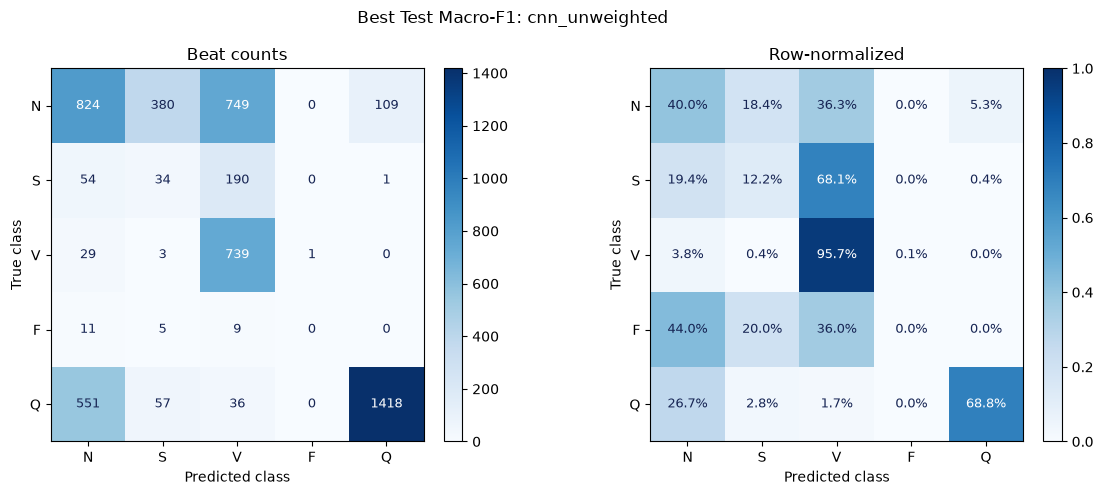

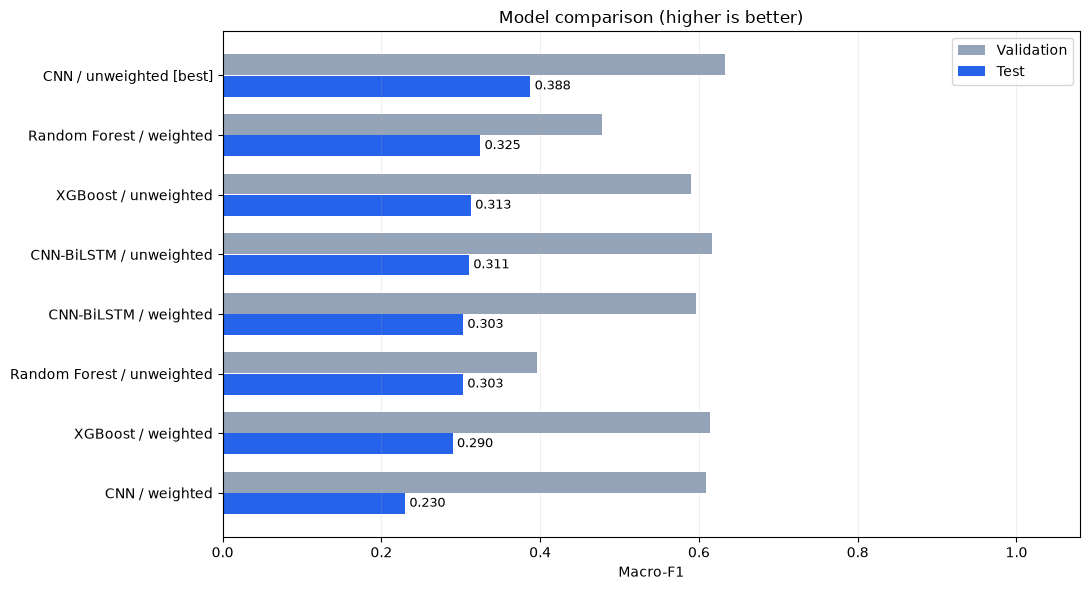

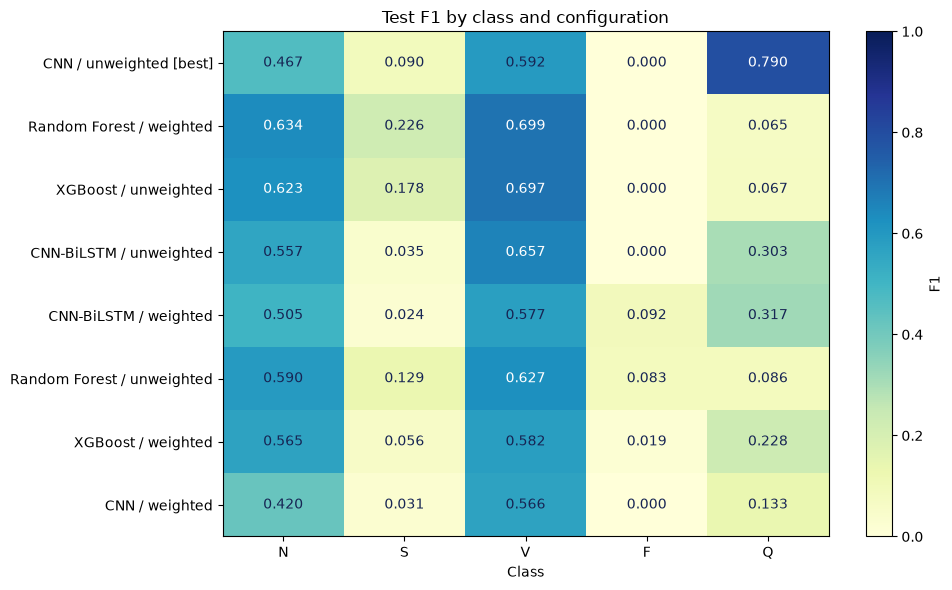

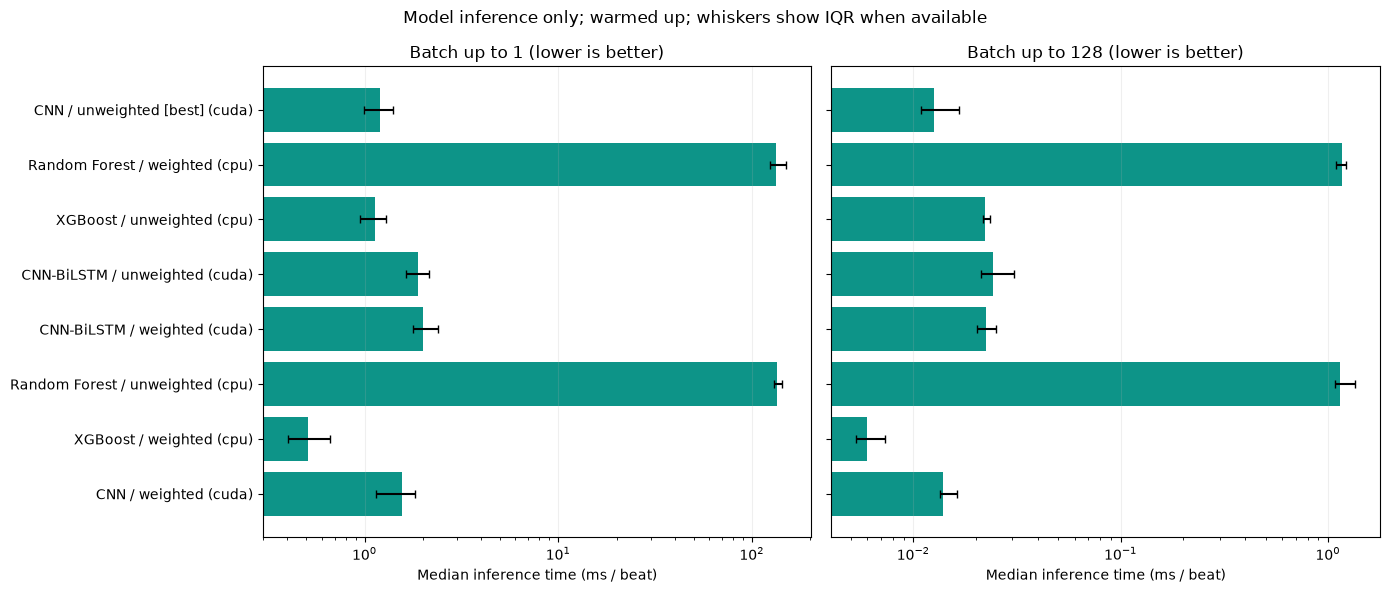

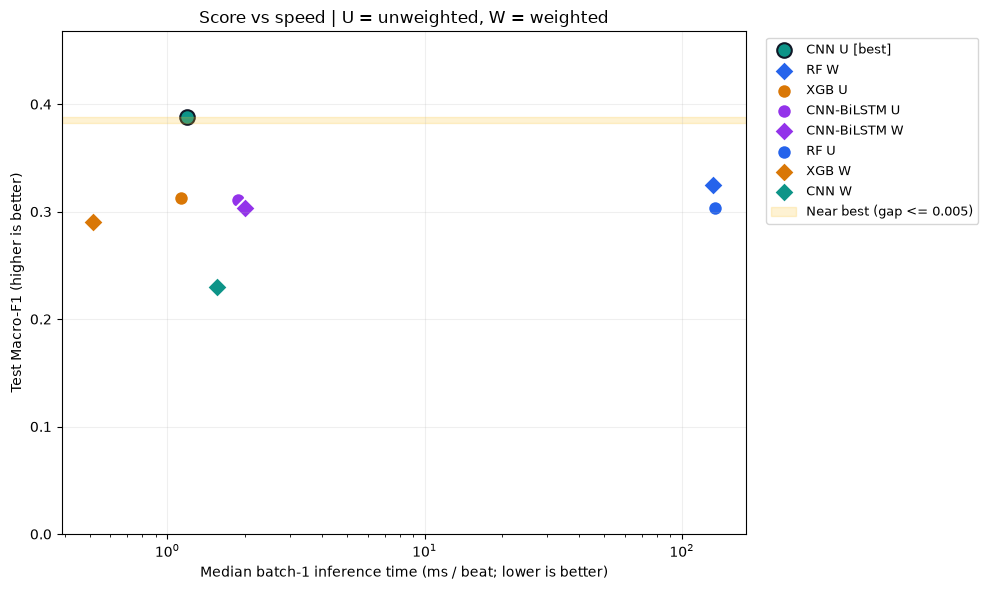

Model,Weighting,F1 (macro),Inference (ms/beat)
CNN (best),Unweighted,0.388,1.195


In [16]:
# รันกราฟจากผลที่บันทึกไว้ได้ โดยไม่ประเมินหรือจับเวลาใหม่
comparison = pd.read_csv(REPORTS / 'final/comparison.csv')
selection = read_json(ARTIFACTS / 'selection.json')
evaluation = read_json(REPORTS / 'final/evaluation.json')
if selection.get('selection_metric') != 'test_macro_f1':
    raise ValueError('รัน notebook 11 ส่วนประเมินและเลือกผู้ชนะจาก Test ก่อนวาดกราฟ')
if evaluation['selection_hash'] != sha256(ARTIFACTS / 'selection.json'):
    raise ValueError('รายงานไม่ตรงกับ selection; รัน notebook 11 ใหม่')
evaluation_figures, near_best = plot_evaluation_summary(
    comparison, selection, REPORTS / 'final', tolerance=NEAR_BEST_TOLERANCE)
plt.show()
for fig in evaluation_figures:
    plt.close(fig)
near_best_summary = performance_table(near_best)
near_best_summary[['Model', 'Weighting', 'F1 (macro)', 'Inference (ms/beat)']].style.hide(axis='index').format({
    'F1 (macro)': '{:.3f}', 'Inference (ms/beat)': '{:.3f}'
}).set_caption(f'Models within {NEAR_BEST_TOLERANCE:g} of best Test Macro-F1, ordered by inference time')
